# Boiling point of water against altitude: barometric models vs reference data

**Question.** How well does the simple barometric formula predict the boiling point of water at altitude, compared with published measurements?

**What this notebook does.** It compares four model variants. Each pairs a pressure model (isothermal barometric formula, or the International Standard Atmosphere, ISA) with a boiling-temperature model (constant-enthalpy Clausius-Clapeyron, or IAPWS-IF97 saturation). Each variant's predicted boiling temperature is compared with a reference table, grouped by altitude band.

**Data.** `mini_demo_data.json` holds 100 evenly spaced rows of the Engineering ToolBox "boiling point vs altitude" table, plus the source log. That table is a published tabulated table whose method is not stated, so it is used as a benchmark only. **No measured rows were obtained in this round.** The NIST RP1229 PDF had no readable table text, and the CRC Handbook and Keene (1995) were not obtained.

**Status: UNTESTED.** There is no measured comparison and no accuracy claim. The computed reference is shown only as context.

**What you will see.** Unit checks, residual statistics per altitude band for each variant, and two plots of the residuals.

## Install dependencies

Packages that are not pre-installed on Colab are always installed. Pre-installed packages are installed locally only, at Colab's exact versions, so that the local environment matches Colab.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Not pre-installed on Colab: always install
_pip('iapws==1.5.5')
_pip('loguru==0.8.0')

# Pre-installed on Colab: install locally only, at Colab's exact versions
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0')

## Imports and figure style

The original import block is kept as written. `matplotlib` is added for the plots, together with the shared figure style.

In [2]:
import csv
import json
import math
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from iapws import IAPWS97
from loguru import logger

import matplotlib.pyplot as plt

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})

Matplotlib is building the font cache; this may take a moment.


## Load the data

The data are read from the GitHub raw URL. If that is unavailable (for example before the repository is published), the local `mini_demo_data.json` next to this notebook is used.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-fde7b3-simple-barometric-model-vs-boiling-point/main/round-2/experiment-2/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print("datasets:", [(d["dataset"], len(d["examples"])) for d in data["datasets"]])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
datasets: [('engtoolbox_boiling_altitude', 100)]


## Config

`N_ROWS` is the number of reference rows used. The rows are spread evenly across the table. It starts at the smallest value that gives output, and is raised step by step in testing.

In [5]:
# Tunable parameters
N_ROWS = 100  # number of computed reference rows used (all 100 rows in the mini file)

## Constants and model functions

These are the original constants and functions, unchanged. The only change is that `WS` is the notebook's folder, because `__file__` does not exist in a notebook.

In [6]:
WS = Path.cwd()  # the notebook's folder (__file__ is not defined in a notebook)
RES = WS / "results"
RES.mkdir(parents=True, exist_ok=True)

# Constants (plan section STEP 3/4)
G = 9.80665
M_AIR = 0.028964
R_GAS = 8.314462
T0 = 288.15
P0 = 101325.0
LAPSE = 0.0065
H_SCALE = R_GAS * T0 / (M_AIR * G)  # about 8434 m
TB_K = 373.124
PB_PA = 101325.0
DH = 40650.0  # J/mol
TB_ALT_K = 373.15  # anchor check
BANDS = [(0.0, 3000.0, "0-3 km"), (3000.0, 6000.0, "3-6 km"), (6000.0, math.inf, "6 km and above")]


def p_iso(h):
    return P0 * math.exp(-h / H_SCALE)


def p_isa(h):
    base = 1.0 - LAPSE * h / T0
    if base <= 0:
        raise ValueError(f"altitude {h} m above ISA troposphere model range")
    return P0 * base ** (G * M_AIR / (R_GAS * LAPSE))


def h_from_p_isa(p):
    return (T0 / LAPSE) * (1.0 - (p / P0) ** (R_GAS * LAPSE / (G * M_AIR)))


def t_ce(p, tb=TB_K):
    return 1.0 / (1.0 / tb - (R_GAS / DH) * math.log(p / PB_PA))


_iapws_cache = {}


def t_iapws(p):
    key = round(p, 3)
    if key not in _iapws_cache:
        _iapws_cache[key] = float(IAPWS97(P=p / 1e6, x=0).T)
    return _iapws_cache[key]


VARIANTS = {
    "V1": ("isothermal", "constant_enthalpy_CC"),
    "V2": ("isothermal", "IAPWS_IF97"),
    "V3": ("ISA", "constant_enthalpy_CC"),
    "V4": ("ISA", "IAPWS_IF97"),
}


def model_T(variant, p):
    _, tmodel = VARIANTS[variant]
    return t_ce(p) if tmodel == "constant_enthalpy_CC" else t_iapws(p)


def model_P(variant, h):
    pmodel, _ = VARIANTS[variant]
    return p_iso(h) if pmodel == "isothermal" else p_isa(h)


def band_of(h):
    for lo, hi, name in BANDS:
        if lo <= h < hi:
            return name
    return None


def stats(res):
    res = np.asarray(res, dtype=float)
    if res.size == 0:
        return {"n": 0, "bias_K": None, "MAE_K": None, "maxAE_K": None}
    return {
        "n": int(res.size),
        "bias_K": float(res.mean()),
        "MAE_K": float(np.abs(res).mean()),
        "maxAE_K": float(np.abs(res).max()),
    }

## Logger and unit checks

The original `main()` function is split into cells. Its body is kept in order, and the logger is set up here. The sanity checks confirm the constants and the IAPWS-IF97 value at 101.325 kPa.

In [7]:
logger.remove()
logger.add(sys.stdout, level="INFO")
logger.add(RES / "run.log", level="DEBUG", rotation="5 MB")

# Constant sanity checks (T1, T3, T4)
assert abs(t_ce(PB_PA) - TB_K) < 1e-9, "T1 failed"
assert abs(p_isa(0.0) - P0) < 1e-6, "T3 failed (sea level)"
assert abs(p_isa(11000.0) - 22632.0) < 30.0, "T3 failed (11 km)"
assert abs(p_iso(H_SCALE) - P0 / math.e) < 1e-6, "T3 failed (isothermal)"
assert abs(760 * 133.322 - 101325) < 1.0, "T4 failed"
logger.info("Unit checks T1, T3, T4 passed; T2 IAPWS at 101.325 kPa = {:.4f} K", t_iapws(PB_PA))

2026-11-19 18:08:09.935 -08:00 | INFO     | __main__:<module>:11 - Unit checks T1, T3, T4 passed; T2 IAPWS at 101.325 kPa = 373.1243 K


## Measured set and computed reference rows

The measured set comes from the `measured_pairs` list in the mini file. It is empty in this round, so no measured comparison is made. The computed reference rows are used as context only and are never labelled as measured.

In [8]:
# Measured set (may be empty): zero rows in this round
measured = pd.DataFrame(data["measured_pairs"])
n_measured = len(measured)
logger.info("Measured rows: {}", n_measured)

# Computed reference rows (context only). Rows are spread evenly across each dataset, N_ROWS of them.
ref_rows = []
for ds in data["datasets"]:
    rows = ds["examples"]
    step = max(1, len(rows) // N_ROWS)
    for ex in rows[::step][:N_ROWS]:
        inp = json.loads(ex["input"])
        ref_rows.append({
            "data_type": ex["metadata_data_type"],
            "source_id": ex["metadata_source_id"],
            "altitude_m": float(inp["altitude_m"]),
            "T_ref_K": float(ex["output"]),
            "pressure_ref_Pa": ex["metadata_pressure_Pa"],
        })
ref = pd.DataFrame(ref_rows)
logger.info("Computed reference rows: {} ({})", len(ref), ref["data_type"].value_counts().to_dict())

2026-11-19 18:08:09.984 -08:00 | INFO     | __main__:<module>:4 - Measured rows: 0


2026-11-19 18:08:10.061 -08:00 | INFO     | __main__:<module>:21 - Computed reference rows: 100 ({'computed_unknown_method': 100})


## Sea-level confirmation

At 101.325 kPa, all four variants must agree with 373.124 K within 0.05 K.

In [9]:
# Sea-level confirmation (T7): all variants at 101.325 kPa must match 373.124 K within 0.05 K
sea = {v: model_T(v, PB_PA) for v in VARIANTS}
sea_ok = all(abs(t - TB_K) <= 0.05 for t in sea.values())
logger.info("Sea-level confirmation: {} {}", {k: round(v, 3) for k, v in sea.items()}, "PASS" if sea_ok else "FAIL")

2026-11-19 18:08:10.100 -08:00 | INFO     | __main__:<module>:4 - Sea-level confirmation: {'V1': 373.124, 'V2': 373.124, 'V3': 373.124, 'V4': 373.124} PASS


## Per-row residuals and band statistics (computed context)

Each variant's predicted boiling temperature is compared with the reference at each row's altitude, using the model pressure for that altitude. The residuals are then summarised per altitude band. These are computed-context statistics, not measured ones.

In [10]:
# Per-row residuals on the computed reference (context)
rows_out = []
for _, r in ref.iterrows():
    h = r["altitude_m"]
    rec = {
        "data_type": r["data_type"],
        "source_id": r["source_id"],
        "altitude_m": h,
        "band": band_of(h),
        "T_ref_K": r["T_ref_K"],
    }
    for v in VARIANTS:
        rec[f"{v}_resid_K"] = model_T(v, model_P(v, h)) - r["T_ref_K"]
    rows_out.append(rec)
per_row = pd.DataFrame(rows_out)

# Band statistics on the computed reference, labelled as context
band_rows = []
for dtype, grp in per_row.groupby("data_type"):
    for _, _, bname in BANDS:
        sub = grp[grp["band"] == bname]
        for v in VARIANTS:
            s = stats(sub[f"{v}_resid_K"].values)
            band_rows.append({"evidence": "computed_context", "data_type": dtype, "band": bname, "variant": v, **s})

# Measured band statistics: only if rows exist
meas_band_rows = []
if n_measured > 0:
    measured["altitude_implied_m"] = measured["pressure_Pa"].apply(h_from_p_isa)
    measured["band"] = measured["altitude_implied_m"].apply(band_of)
    for _, _, bname in BANDS:
        sub = measured[measured["band"] == bname]
        for v in VARIANTS:
            res = [model_T(v, float(p)) - float(t) for p, t in zip(sub["pressure_Pa"], sub["T_measured_K"])]
            meas_band_rows.append({"evidence": "measured", "band": bname, "variant": v, **stats(res)})
band_df = pd.DataFrame(band_rows + meas_band_rows)
band_df.to_csv(RES / "band_stats.csv", index=False)
per_row.to_csv(RES / "per_row_residuals.csv", index=False)

## Anchor check and sign counts

The anchor check moves the boiling-point anchor from 373.124 K to 373.15 K, for V1 and V3. The sign count compares V1 with V3 row by row.

In [11]:
# Anchor check (V1 and V3 with 373.15 K), computed reference only
anchor = {}
for v in ("V1", "V3"):
    diffs = []
    for _, r in per_row.iterrows():
        p = model_P(v, r["altitude_m"])
        diffs.append(t_ce(p, TB_ALT_K) - t_ce(p, TB_K))
    anchor[v] = float(np.mean(diffs))

# V1 minus V3 sign per computed row
sign = {"V1_gt_V3": 0, "V1_lt_V3": 0, "equal": 0}
for _, r in per_row.iterrows():
    diff = r["V1_resid_K"] - r["V3_resid_K"]
    key = "V1_gt_V3" if diff > 1e-9 else ("V1_lt_V3" if diff < -1e-9 else "equal")
    sign[key] += 1

## Summary and output files

The source log is read from the mini file (its `sources` list), not from a `sources/` folder. The outputs are written to `results/`.

In [12]:
sources = {"sources": data["sources"]}  # source log, carried in mini_demo_data.json
summary = {
    "n_measured": n_measured,
    "sources_retained": sum(1 for s in sources["sources"] if s.get("rows_retained", 0) > 0),
    "measured_claim": "none" if n_measured == 0 else "see band_stats.csv, evidence=measured",
    "sea_level_confirmation_pass": bool(sea_ok),
    "sea_level_T_K": sea,
    "anchor_shift_mean_K_373.15_minus_373.124": anchor,
    "sign_V1_minus_V3_computed_rows": sign,
    "computed_reference_rows": int(len(per_row)),
    "figure": "not drawn: no measured band has n >= 3",
}
(RES / "sources_summary.json").write_text(json.dumps(summary, indent=2))

def example_from_row(row: dict, dataset_label: str) -> dict:
    """One exp_gen_sol_out example: input/output strings plus flat metadata_* and predict_* fields."""
    inp = {"altitude_m": row["altitude_m"]}
    if "pressure_Pa" in row and row.get("pressure_Pa") is not None:
        inp["pressure_Pa"] = float(row["pressure_Pa"])
    ex = {
        "input": json.dumps(inp, sort_keys=True),
        "output": f"{float(row['T_ref_K']):.4f}" if "T_ref_K" in row else f"{float(row['T_measured_K']):.4f}",
        "metadata_dataset_label": dataset_label,
        "metadata_data_type": str(row.get("data_type", "measured")),
        "metadata_source_id": str(row.get("source_id", "")),
        "metadata_band": str(row.get("band")),
    }
    for v in VARIANTS:
        key = f"{v}_resid_K"
        if key in row:
            ex[f"predict_{v}_resid_K"] = f"{float(row[key]):.4f}"
    return ex


context_examples = [
    example_from_row(r, "computed_reference_context")
    for r in per_row.to_dict(orient="records")
]
datasets = [{"dataset": "computed_reference_context", "examples": context_examples}]
if n_measured > 0:
    measured_examples = [
        example_from_row(r, "measured")
        for r in measured.to_dict(orient="records")
    ]
    datasets.insert(0, {"dataset": "measured_pairs", "examples": measured_examples})

out = {
    "metadata": {
        "status": "untested" if n_measured == 0 else "measured_comparison",
        "statement": (
            "No measured comparison; no accuracy claim; computed reference shown only as context."
            if n_measured == 0 else "Measured comparison computed; see band statistics and n per band."
        ),
        "n_measured": n_measured,
        "n_computed_reference": int(len(per_row)),
        "summary": summary,
        "band_statistics": band_df.to_dict(orient="records"),
    },
    "datasets": datasets,
}


def trimmed(n: int) -> dict:
    """Same structure, first n examples per dataset."""
    return {
        "metadata": out["metadata"],
        "datasets": [{"dataset": d["dataset"], "examples": d["examples"][:n]} for d in out["datasets"]],
    }


(RES / "full_method_out.json").write_text(json.dumps(out, indent=2, default=str))
(RES / "method_out.json").write_text(json.dumps(out, indent=2, default=str))
(RES / "mini_method_out.json").write_text(json.dumps(trimmed(3), indent=2, default=str))
(RES / "preview_method_out.json").write_text(json.dumps(trimmed(5), indent=2, default=str))
logger.info("Wrote outputs. Status: {}, examples: {}", out["metadata"]["status"], sum(len(d["examples"]) for d in datasets))

2026-11-19 18:08:11.827 -08:00 | INFO     | __main__:<module>:75 - Wrote outputs. Status: untested, examples: 100


## Results: table and figures

The table shows the bias (model minus reference, in kelvin) for each variant and altitude band. The row counts are shown beside it. Everything here is computed context, because no measured rows exist in this round. The variants are coloured by role: V1 (the simple isothermal barometric formula the question asks about) is the method colour.

Bias (model minus computed reference), K. Context only, not measured:
variant            V1     V2     V3     V4
band                                      
0-3 km          0.197  0.287  0.087  0.178
3-6 km          0.479  0.783 -0.299  0.026
6 km and above  0.475  1.048 -1.702 -1.058

Rows per band:
variant         V1  V2  V3  V4
band                          
0-3 km          32  32  32  32
3-6 km          31  31  31  31
6 km and above  34  34  34  34


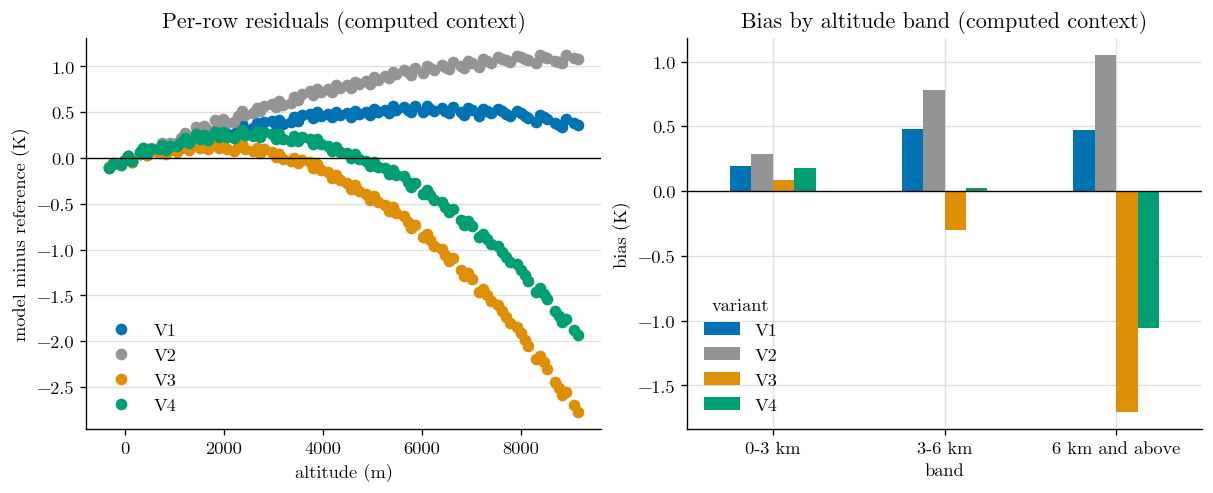

In [13]:
# Key results, computed context only (no measured rows in this round)
ctx = band_df[band_df["evidence"] == "computed_context"]
table = ctx.pivot_table(index="band", columns="variant", values="bias_K", aggfunc="first")
print("Bias (model minus computed reference), K. Context only, not measured:")
print(table.round(3).to_string())
print("\nRows per band:")
print(ctx.pivot_table(index="band", columns="variant", values="n", aggfunc="first").to_string())

# Colour by role: V1 is the simple barometric formula the question asks about
roles = {"V1": "method", "V2": "baseline", "V3": "other_1", "V4": "other_2"}
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for v, role in roles.items():
    ax[0].plot(per_row["altitude_m"], per_row[f"{v}_resid_K"], marker="o", linestyle="none", color=COLOURS[role], label=v)
ax[0].axhline(0, color="black", linewidth=0.8)
ax[0].set_xlabel("altitude (m)")
ax[0].set_ylabel("model minus reference (K)")
ax[0].set_title("Per-row residuals (computed context)")
ax[0].legend()

table.plot(kind="bar", ax=ax[1], color=[COLOURS[r] for r in roles.values()], legend=True)
ax[1].axhline(0, color="black", linewidth=0.8)
ax[1].set_ylabel("bias (K)")
ax[1].set_title("Bias by altitude band (computed context)")
ax[1].tick_params(axis="x", rotation=0)
plt.show()

## Interpreting the results

**What the numbers show (computed context only).** Each bias is the model's boiling temperature minus the Engineering ToolBox value, in kelvin. A positive bias means the model is hotter than the table.

- **V1 (isothermal pressure, constant-enthalpy step)**, the simple barometric formula the question asks about: bias +0.20 K at 0–3 km, +0.48 K at 3–6 km and +0.47 K at 6 km and above.
- **V3 (ISA pressure, constant-enthalpy step)**: +0.09 K, −0.30 K and −1.70 K. It is the only variant below the table in the 3–6 km band, and its gap grows with altitude above 3 km.
- **V4 (ISA pressure, IAPWS-IF97)**: +0.18 K, +0.03 K and −1.06 K. It is below the table at 6 km and above, but by less than V3.
- **V2 (isothermal pressure, IAPWS-IF97)**: the largest positive bias in every band (+0.29 K, +0.78 K, +1.05 K).

At sea level all four variants give 373.124 K (the IAPWS variants 373.1243 K), so they agree there. Moving the anchor from 373.124 K to 373.15 K shifts V1 and V3 by about +0.024 K, which is small next to the band biases.

**What this does not show.** The ToolBox table's method is not stated, so these residuals measure agreement with one tabulated table, not accuracy against measurement. The mini file holds 100 of the table's 125 rows, so the 6 km and above figure is close to, but not the same as, the artifact's full-table value of −1.72 K for V3. The reference is also not measured data. With **zero measured rows**, the question of how well the simple barometric formula predicts measured boiling points is **unanswered**: there is no accuracy claim, and the 6 km and above band has no measured data at all.